In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    auc
)

In [3]:
# Cargar la base de recursos humanos
data = pd.read_csv("recursos_humanos.csv")

data

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low
...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0.57,2,151,3,0,1,0,support,low
14995,0.37,0.48,2,160,3,0,1,0,support,low
14996,0.37,0.53,2,143,3,0,1,0,support,low
14997,0.11,0.96,6,280,4,0,1,0,support,low


In [4]:
# Convertir variables categóricas a numéricas
data_encoded = pd.get_dummies(
    data,
    columns=["sales", "salary"],
    dtype=int
)

data_encoded.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales_IT,sales_RandD,...,sales_hr,sales_management,sales_marketing,sales_product_mng,sales_sales,sales_support,sales_technical,salary_high,salary_low,salary_medium
0,0.38,0.53,2,157,3,0,1,0,0,0,...,0,0,0,0,1,0,0,0,1,0
1,0.80,0.86,5,262,6,0,1,0,0,0,...,0,0,0,0,1,0,0,0,0,1
2,0.11,0.88,7,272,4,0,1,0,0,0,...,0,0,0,0,1,0,0,0,0,1
3,0.72,0.87,5,223,5,0,1,0,0,0,...,0,0,0,0,1,0,0,0,1,0
4,0.37,0.52,2,159,3,0,1,0,0,0,...,0,0,0,0,1,0,0,0,1,0


In [5]:
# Revisar la distribución de empleados
print("Cantidad de empleados por categoría:")
print(data["left"].value_counts())

print("\nPorcentajes:")
print(data["left"].value_counts(normalize=True) * 100)

Cantidad de empleados por categoría:
left
0    11428
1     3571
Name: count, dtype: int64

Porcentajes:
left
0    76.191746
1    23.808254
Name: proportion, dtype: float64


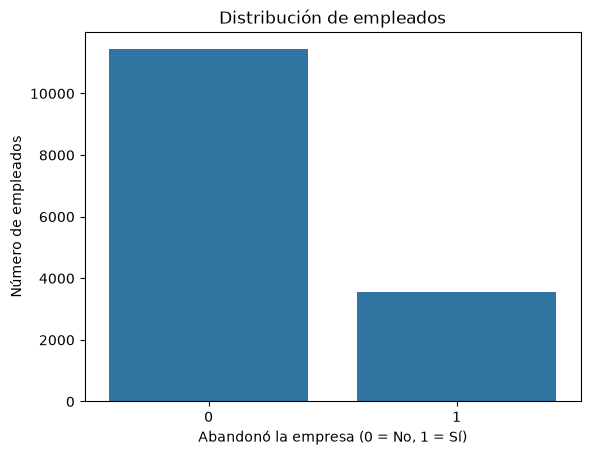

In [6]:
# Gráfica de distribución de empleados
sns.countplot(data=data, x="left")

plt.title("Distribución de empleados")
plt.xlabel("Abandonó la empresa (0 = No, 1 = Sí)")
plt.ylabel("Número de empleados")
plt.show()

In [7]:
# Separar variables predictoras y variable objetivo
X = data_encoded.drop("left", axis=1)
y = data_encoded["left"]

print("Variables predictoras:", X.shape)
print("Variable objetivo:", y.shape)

Variables predictoras: (14999, 20)
Variable objetivo: (14999,)


In [8]:
# Dividir los datos en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Datos de entrenamiento:", X_train.shape)
print("Datos de prueba:", X_test.shape)

Datos de entrenamiento: (11999, 20)
Datos de prueba: (3000, 20)


In [9]:
# Normalizar los datos
scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Primeros 5 registros normalizados:")
print(X_train_scaled[:5])

Primeros 5 registros normalizados:
[[0.7032967  0.40625    0.4        0.70560748 0.25       0.
  0.         0.         0.         0.         0.         0.
  0.         0.         1.         0.         0.         0.
  1.         0.        ]
 [0.75824176 1.         0.6        0.65420561 0.375      0.
  0.         0.         0.         0.         0.         0.
  0.         0.         1.         0.         0.         0.
  0.         1.        ]
 [0.01098901 0.296875   0.         0.70560748 0.25       0.
  0.         0.         0.         0.         0.         0.
  0.         0.         1.         0.         0.         0.
  0.         1.        ]
 [0.54945055 0.234375   0.         0.14018692 0.125      0.
  0.         0.         0.         0.         0.         0.
  0.         0.         1.         0.         0.         0.
  0.         1.        ]
 [0.64835165 0.1875     0.4        0.72429907 0.25       0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0

In [10]:
# Comparar KNN con valores de k del 1 al 20
resultados = []

for k in range(1, 21):
    modelo = KNeighborsClassifier(n_neighbors=k)
    modelo.fit(X_train_scaled, y_train)

    y_pred = modelo.predict(X_test_scaled)

    resultados.append({
        "K": k,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred)
    })

comparacion = pd.DataFrame(resultados)
comparacion

,K,Accuracy,Precision,Recall,F1-score
0,1,0.966000,0.903694,0.959384,0.930707
1,2,0.962000,0.924929,0.914566,0.919718
2,3,0.949667,0.870883,0.925770,0.897488
3,4,0.948667,0.900000,0.882353,0.891089
4,5,0.942333,0.868027,0.893557,0.880607
5,6,0.947000,0.895863,0.879552,0.887633
6,7,0.944333,0.882517,0.883754,0.883135
7,8,0.944000,0.888889,0.873950,0.881356
8,9,0.940333,0.868966,0.882353,0.875608
9,10,0.941000,0.877637,0.873950,0.875789


In [11]:
# Entrenar el modelo con K óptimo
k_optimo = 1

modelo_final = KNeighborsClassifier(n_neighbors=k_optimo)
modelo_final.fit(X_train_scaled, y_train)

y_pred = modelo_final.predict(X_test_scaled)

print("K seleccionado:", k_optimo)
print(classification_report(y_test, y_pred))

K seleccionado: 1
              precision    recall  f1-score   support

           0       0.99      0.97      0.98      2286
           1       0.90      0.96      0.93       714

    accuracy                           0.97      3000
   macro avg       0.95      0.96      0.95      3000
weighted avg       0.97      0.97      0.97      3000



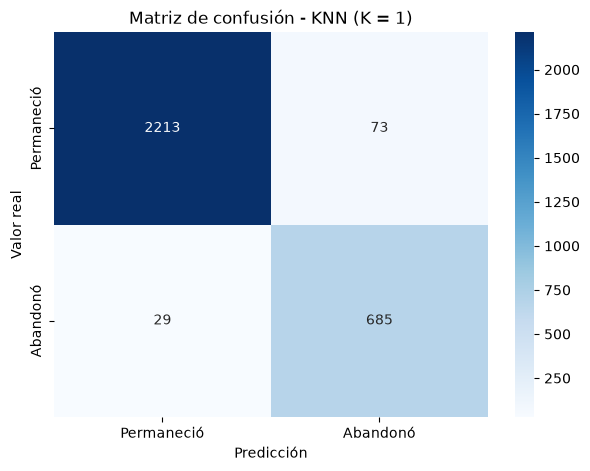

In [12]:
# Matriz de confusión de KNN con K = 1
matriz = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Permaneció", "Abandonó"],
    yticklabels=["Permaneció", "Abandonó"]
)

plt.title("Matriz de confusión - KNN (K = 1)")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.show()

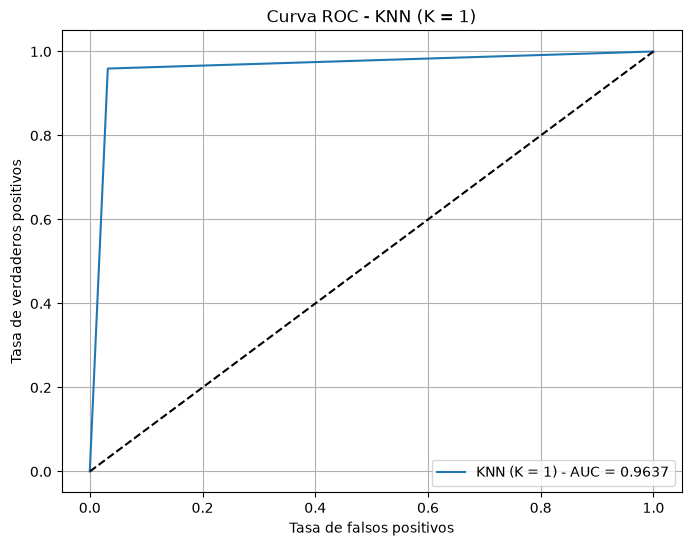

AUC: 0.9637251225949699


In [13]:
# Curva ROC de KNN con K = 1
y_prob = modelo_final.predict_proba(X_test_scaled)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_valor = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"KNN (K = 1) - AUC = {auc_valor:.4f}")
plt.plot([0, 1], [0, 1], "k--")

plt.title("Curva ROC - KNN (K = 1)")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.legend()
plt.grid()
plt.show()

print("AUC:", auc_valor)